# 6. Análisis multivariado (2.4)

Se usan las 18 predictoras del panel de entrenamiento: conteos en log1p, magnitudes faltantes
imputadas con la mediana y todo estandarizado. Hay tres preguntas:

1. ¿Cuál es la **dimensionalidad efectiva**? (PCA)
2. ¿Hay **observaciones atípicas multivariadas**? (Mahalanobis robusta e Isolation Forest)
3. ¿Hay **subpoblaciones** de celdas con comportamientos distintos? (k-means y t-SNE como apoyo visual)

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Datos estandarizados (imputación con la mediana) para PCA, atípicos multivariados y clustering
from sklearn.decomposition import PCA
from sklearn.covariance import MinCovDet
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
ev_, X, info, tr, gp, te = datos.panel_completo()
P = datos.panel_dataframe(X, info, tr)
conteos = [c for c in X.columns if c.startswith(("n_", "n35", "vec", "n_mismo"))]
Z = P[X.columns].copy()
Z[conteos] = np.log1p(Z[conteos])
Z = Z.fillna(Z.median())
Z = (Z - Z.mean()) / Z.std()

## 6.1 PCA: varianza explicada y estructura

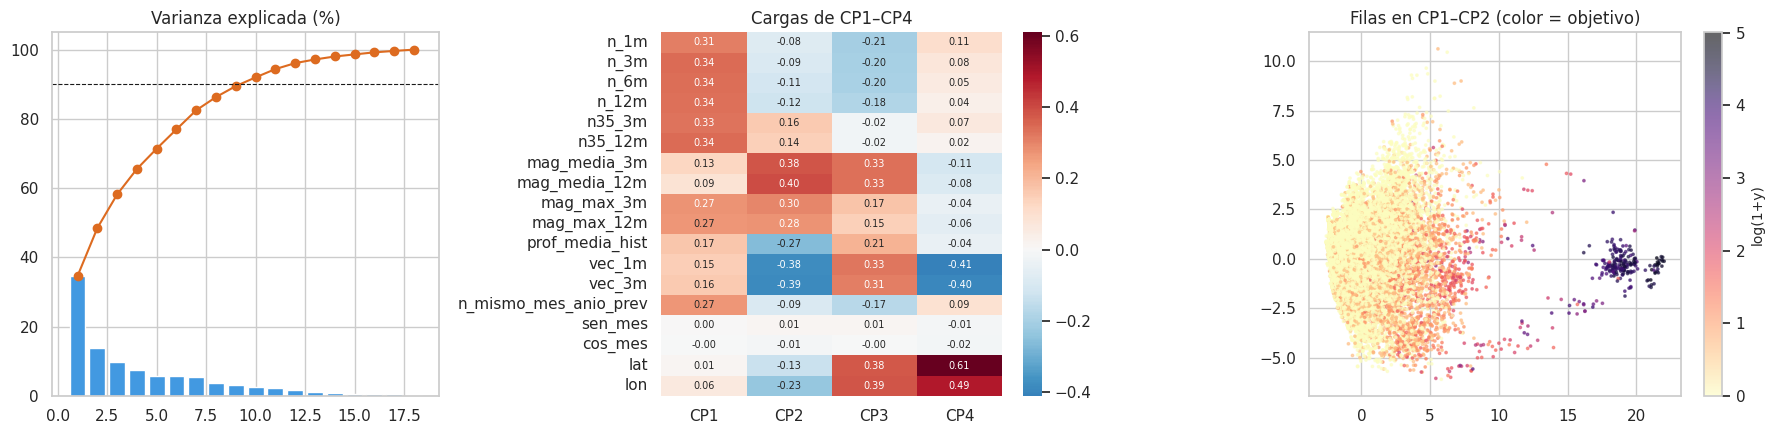

**Interpretación.**
- **CP1** explica el 34,6 % de la varianza. Tiene cargas positivas y parecidas (≈ 0,34) en todos
  los **conteos de la propia celda**, y menores en los de la vecindad (0,15). Es un eje de **«nivel de actividad»**,
  y el color de la figura muestra que ordena bien el objetivo.
- **CP2** (13,8 %) contrapone las **magnitudes** de la ventana (cargas de +0,3 a +0,4) a la **actividad vecina y la
  profundidad** (≈ −0,3 a −0,4): separa celdas con sismos más grandes de celdas profundas rodeadas de actividad, como el entorno del nido.
- **CP3 y CP4** recogen sobre todo la **ubicación** (lat, lon) y la vecindad.
- **Dimensionalidad efectiva.** Se necesitan **10 componentes** para el 90 % de la varianza, de 18 variables: hay redundancia (los
  bloques del capítulo 5), pero no colapso a uno o dos ejes. Las variables de calendario (`sen_mes`, `cos_mes`) tienen cargas ≈ 0 en las
  cuatro primeras componentes: son ortogonales al resto y ocupan componentes propias.
- **Uso.** El PCA es solo exploratorio. Los modelos usan las variables originales dentro de su Pipeline, y no se ajusta ningún
  PCA con datos de prueba.

In [3]:
# PCA: varianza explicada y cargas de las primeras componentes
pca = PCA(random_state=cfg.SEMILLA).fit(Z)
var = pd.DataFrame({"componente": np.arange(1, len(X.columns) + 1), "varianza_%": 100 * pca.explained_variance_ratio_})
var["acumulada_%"] = var["varianza_%"].cumsum()
cargas = pd.DataFrame(pca.components_[:4].T, index=X.columns, columns=["CP1", "CP2", "CP3", "CP4"])
eda.guardar_tabla(var, "pca_varianza.csv"); eda.guardar_tabla(cargas.reset_index(), "pca_cargas.csv")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [1, 1.1, 1.2]})
axes[0].bar(var.componente, var["varianza_%"], color="#4299e1"); axes[0].plot(var.componente, var["acumulada_%"], "o-", c="#dd6b20")
axes[0].axhline(90, ls="--", c="k", lw=0.8); axes[0].set_title("Varianza explicada (%)")
sns.heatmap(cargas, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[1], annot_kws={"size": 7}); axes[1].set_title("Cargas de CP1–CP4")
S = pca.transform(Z)[:, :2]
sc = axes[2].scatter(S[:, 0], S[:, 1], c=P.log_y, s=3, cmap="magma_r", alpha=0.6)
plt.colorbar(sc, ax=axes[2], label="log(1+y)"); axes[2].set_title("Filas en CP1–CP2 (color = objetivo)")
plt.tight_layout(); eda.guardar_figura(fig, "06_pca.png"); plt.show()
k90 = int((var["acumulada_%"] < 90).sum() + 1)
md(f"""**Interpretación.**
- **CP1** explica el {es(var['varianza_%'][0], 1)} % de la varianza. Tiene cargas positivas y parecidas (≈ {es(cargas.loc['n_3m', 'CP1'], 2)}) en todos
  los **conteos de la propia celda**, y menores en los de la vecindad ({es(cargas.loc['vec_1m', 'CP1'], 2)}). Es un eje de **«nivel de actividad»**,
  y el color de la figura muestra que ordena bien el objetivo.
- **CP2** ({es(var['varianza_%'][1], 1)} %) contrapone las **magnitudes** de la ventana (cargas de +0,3 a +0,4) a la **actividad vecina y la
  profundidad** (≈ −0,3 a −0,4): separa celdas con sismos más grandes de celdas profundas rodeadas de actividad, como el entorno del nido.
- **CP3 y CP4** recogen sobre todo la **ubicación** (lat, lon) y la vecindad.
- **Dimensionalidad efectiva.** Se necesitan **{k90} componentes** para el 90 % de la varianza, de 18 variables: hay redundancia (los
  bloques del capítulo 5), pero no colapso a uno o dos ejes. Las variables de calendario (`sen_mes`, `cos_mes`) tienen cargas ≈ 0 en las
  cuatro primeras componentes: son ortogonales al resto y ocupan componentes propias.
- **Uso.** El PCA es solo exploratorio. Los modelos usan las variables originales dentro de su Pipeline, y no se ajusta ningún
  PCA con datos de prueba.""")

## 6.2 Atípicos multivariados

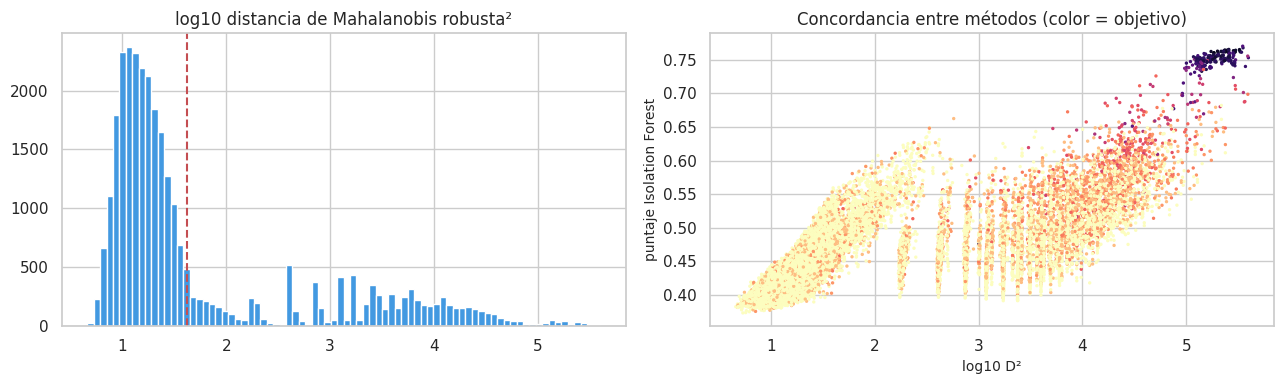

,método,% filas,media y si atípico,media y si no
0,"Mahalanobis robusta (MCD, χ² 99,9 %)",29.03,2.20,0.24
1,Isolation Forest,15.55,3.69,0.28
2,ambos,14.15,4.04,0.28


,,filas atípicas (ambos)
lat,lon,
6.75,-73.25,190
5.25,-73.75,189
7.25,-73.25,188
6.25,-73.75,186
6.75,-73.75,169


In [4]:
# Atípicos multivariados: distancia de Mahalanobis robusta (MCD) e Isolation Forest
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # avisos numéricos de MCD con variables discretas
rng = np.random.default_rng(cfg.SEMILLA)
mcd = MinCovDet(random_state=cfg.SEMILLA, support_fraction=0.75).fit(Z.iloc[rng.choice(len(Z), 8000, replace=False)])
d2 = mcd.mahalanobis(Z)
umbral = stats.chi2.ppf(0.999, Z.shape[1])
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=cfg.SEMILLA, n_jobs=-1).fit(Z)
score = -iso.score_samples(Z)
P["atipico_mahal"] = d2 > umbral
P["atipico_iso"] = iso.predict(Z) == -1
tabla_at = pd.DataFrame({
    "método": ["Mahalanobis robusta (MCD, χ² 99,9 %)", "Isolation Forest", "ambos"],
    "% filas": [100 * P.atipico_mahal.mean(), 100 * P.atipico_iso.mean(), 100 * (P.atipico_mahal & P.atipico_iso).mean()],
    "media y si atípico": [P.loc[P.atipico_mahal, "y"].mean(), P.loc[P.atipico_iso, "y"].mean(), P.loc[P.atipico_mahal & P.atipico_iso, "y"].mean()],
    "media y si no": [P.loc[~P.atipico_mahal, "y"].mean(), P.loc[~P.atipico_iso, "y"].mean(), P.loc[~(P.atipico_mahal & P.atipico_iso), "y"].mean()],
})
celdas_at = P[P.atipico_mahal & P.atipico_iso].groupby(["lat", "lon"]).size().sort_values(ascending=False).head(5)
eda.guardar_tabla(tabla_at, "atipicos_multivariados.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(np.log10(d2), bins=80, color="#4299e1"); ax[0].axvline(np.log10(umbral), c="r", ls="--"); ax[0].set_title("log10 distancia de Mahalanobis robusta²")
ax[1].scatter(np.log10(d2), score, s=2, c=P.log_y, cmap="magma_r"); ax[1].set_xlabel("log10 D²"); ax[1].set_ylabel("puntaje Isolation Forest")
ax[1].set_title("Concordancia entre métodos (color = objetivo)")
plt.tight_layout(); eda.guardar_figura(fig, "06_atipicos.png"); plt.show()
display(tabla_at.round(2))
celdas_at.to_frame("filas atípicas (ambos)")

In [5]:
md(f"""**Interpretación.**
- **Mahalanobis robusta.** Marca el {es(tabla_at['% filas'][0], 1)} % de las filas. Es mucho más que el 0,1 % que se esperaría con datos
  normales: el núcleo robusto (MCD) lo forman las celdas casi inactivas, así que cualquier celda con actividad queda lejos de él.
- **Isolation Forest.** Marca el {es(tabla_at['% filas'][1], 1)} %, y {es(tabla_at['% filas'][2], 1)} % coincide con Mahalanobis.
- **Qué son los atípicos.** Las filas atípicas tienen un objetivo medio de {es(tabla_at['media y si atípico'][2], 1)} sismos, frente a
  {es(tabla_at['media y si no'][2], 2)} en el resto. Se concentran en las celdas **más activas**: el nido de Bucaramanga y sus vecinas aparecen
  como atípicas en prácticamente todos sus meses (tabla). No son errores.
- **Tratamiento.** No se eliminan: son justamente donde está la información sobre los sismos. Eliminarlas sesgaría el modelo
  hacia «no pasa nada». Su influencia en los modelos lineales se controla con log1p y estandarización (capítulo 10). Los
  modelos de árboles del Entregable 2 son robustos a ellas por construcción.""")

**Interpretación.**
- **Mahalanobis robusta.** Marca el 29,0 % de las filas. Es mucho más que el 0,1 % que se esperaría con datos
  normales: el núcleo robusto (MCD) lo forman las celdas casi inactivas, así que cualquier celda con actividad queda lejos de él.
- **Isolation Forest.** Marca el 15,6 %, y 14,1 % coincide con Mahalanobis.
- **Qué son los atípicos.** Las filas atípicas tienen un objetivo medio de 4,0 sismos, frente a
  0,28 en el resto. Se concentran en las celdas **más activas**: el nido de Bucaramanga y sus vecinas aparecen
  como atípicas en prácticamente todos sus meses (tabla). No son errores.
- **Tratamiento.** No se eliminan: son justamente donde está la información sobre los sismos. Eliminarlas sesgaría el modelo
  hacia «no pasa nada». Su influencia en los modelos lineales se controla con log1p y estandarización (capítulo 10). Los
  modelos de árboles del Entregable 2 son robustos a ellas por construcción.

## 6.3 Subpoblaciones de celdas: k-means sobre el perfil de cada celda

- **Unidad de agrupamiento.** Se agrupan **celdas**, no filas: así se responde si hay tipos de
  zonas sísmicas.
- **Perfil de cada celda (entrenamiento):** media de log(1+y), proporción de meses en cero,
  variabilidad (desviación de log(1+y)), proporción de sismos M ≥ 3,5, profundidad media y
  magnitud media.
- **Elección de k:** silueta.

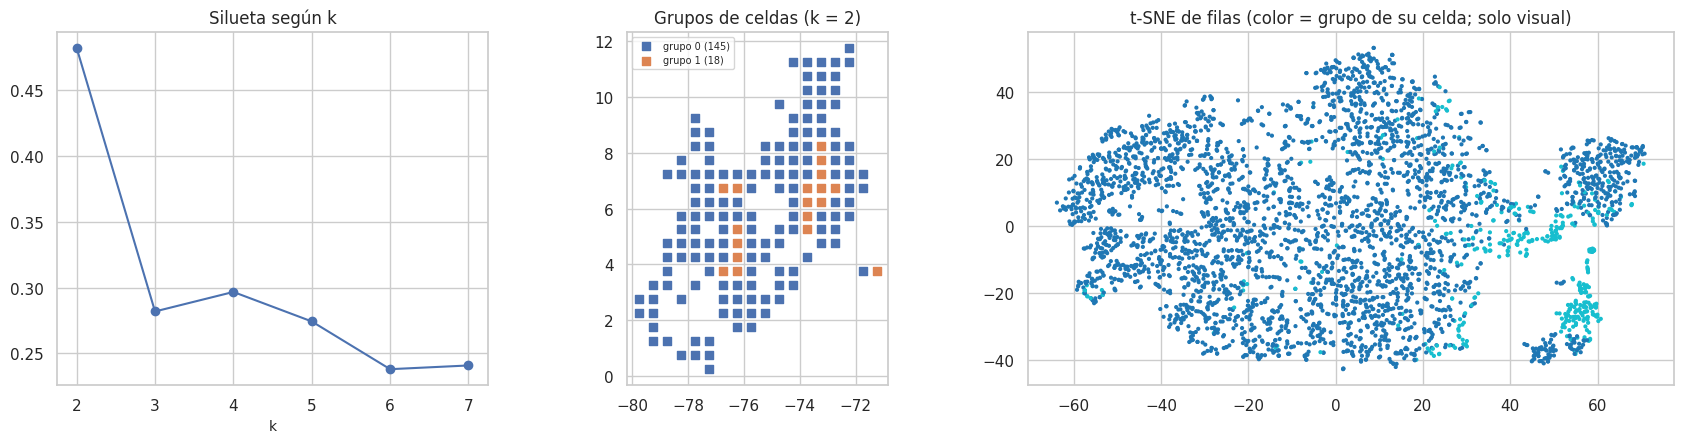

,celdas,media_mensual,ceros,prof_media,mag_media
grupo,,,,,
0,145,0.17,0.81,30.02,2.95
1,18,4.41,0.40,95.54,2.89


In [6]:
# Perfil de cada celda y agrupamiento con K-means (silueta) y t-SNE
perfil = P.groupby("celda").agg(lat=("lat", "first"), lon=("lon", "first"), media_log=("log_y", "mean"),
                               ceros=("y", lambda s: np.mean(s == 0)), variab=("log_y", "std"),
                               frac_m35=("n35_12m", "sum"), n12=("n_12m", "sum"),
                               prof=("prof_media_hist", "last"), mag=("mag_media_12m", "mean"))
perfil["frac_m35"] = perfil.frac_m35 / perfil.n12.replace(0, np.nan)
perfil = perfil.drop(columns="n12").fillna(perfil.median())
F = perfil[["media_log", "ceros", "variab", "frac_m35", "prof", "mag"]]
F = (F - F.mean()) / F.std()
sil = {k: silhouette_score(F, KMeans(k, n_init=20, random_state=cfg.SEMILLA).fit_predict(F)) for k in range(2, 8)}
k_opt = max(sil, key=sil.get)
perfil["grupo"] = KMeans(k_opt, n_init=20, random_state=cfg.SEMILLA).fit_predict(F)
resumen_g = perfil.groupby("grupo").agg(celdas=("lat", "size"), media_mensual=("media_log", lambda s: np.expm1(s).mean()),
                                        ceros=("ceros", "mean"), prof_media=("prof", "mean"), mag_media=("mag", "mean"))
eda.guardar_tabla(perfil.reset_index(), "clusters_celdas.csv")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [0.8, 1, 1.2]})
axes[0].plot(list(sil), list(sil.values()), "o-"); axes[0].set_title("Silueta según k"); axes[0].set_xlabel("k")
for g_, d in perfil.groupby("grupo"):
    axes[1].scatter(d.lon, d.lat, s=40, marker="s", label=f"grupo {g_} ({len(d)})")
axes[1].legend(fontsize=7); axes[1].set_aspect("equal"); axes[1].set_title(f"Grupos de celdas (k = {k_opt})")
sub = P.sample(4000, random_state=cfg.SEMILLA)
emb = TSNE(2, perplexity=40, random_state=cfg.SEMILLA, init="pca").fit_transform(Z.loc[sub.index])
axes[2].scatter(emb[:, 0], emb[:, 1], c=sub.celda.map(perfil.grupo), s=4, cmap="tab10")
axes[2].set_title("t-SNE de filas (color = grupo de su celda; solo visual)")
plt.tight_layout(); eda.guardar_figura(fig, "06_clusters.png"); plt.show()
resumen_g.round(2)

In [7]:
md(f"""**Interpretación.**
- **Número de grupos.** La silueta es máxima con **k = {k_opt}** ({es(sil[k_opt], 2)}): una separación {('clara' if sil[k_opt] > 0.5 else 'moderada')}.
- **Qué separan los grupos.** El **nivel de actividad** (media mensual y proporción de ceros) y la **profundidad**. Uno de ellos reúne
  las celdas muy activas y profundas del nido de Bucaramanga (ver la tabla).
- **t-SNE.** Se usa **solo como apoyo visual**, no para inferir nada. Muestra que las filas de un mismo grupo de celdas tienden a
  ocupar regiones contiguas, con superposición en las celdas de baja actividad.
- **Implicaciones para el modelado.**
  1. Hay subpoblaciones de celdas con dinámicas distintas, así que un modelo global debe recibir variables que identifiquen la
     celda o su régimen (historia propia, profundidad, ubicación). Las 18 variables ya lo hacen.
  2. Los modelos no lineales podrán ajustar relaciones distintas por grupo.
  3. La evaluación debe revisar el desempeño **por grupo de celdas** (capítulo 11), no solo el promedio.""")

**Interpretación.**
- **Número de grupos.** La silueta es máxima con **k = 2** (0,48): una separación moderada.
- **Qué separan los grupos.** El **nivel de actividad** (media mensual y proporción de ceros) y la **profundidad**. Uno de ellos reúne
  las celdas muy activas y profundas del nido de Bucaramanga (ver la tabla).
- **t-SNE.** Se usa **solo como apoyo visual**, no para inferir nada. Muestra que las filas de un mismo grupo de celdas tienden a
  ocupar regiones contiguas, con superposición en las celdas de baja actividad.
- **Implicaciones para el modelado.**
  1. Hay subpoblaciones de celdas con dinámicas distintas, así que un modelo global debe recibir variables que identifiquen la
     celda o su régimen (historia propia, profundidad, ubicación). Las 18 variables ya lo hacen.
  2. Los modelos no lineales podrán ajustar relaciones distintas por grupo.
  3. La evaluación debe revisar el desempeño **por grupo de celdas** (capítulo 11), no solo el promedio.